## 1. Environment check and dependency setup


In [ ]:
import sys
import subprocess
import importlib.util
import shutil
import os

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])

java_path = shutil.which("java")
if java_path is None:
    raise EnvironmentError(
        "Java was not found. Install a 64-bit JDK (Java 8, 11 or 17 are commonly "
        "used with Spark 3.5), set JAVA_HOME, add %JAVA_HOME%\\bin to PATH, "
        "restart VS Code/Jupyter, and run this cell again."
    )

java_check = subprocess.run(
    ["java", "-version"], capture_output=True, text=True
)
print("Java executable:", java_path)
print((java_check.stderr or java_check.stdout).splitlines()[0])

# Installs only packages that are not already importable.
required_packages = {
    "pyspark": "pyspark==3.5.5",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn"
}

missing = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required Python packages are already installed.")

import pyspark
print("PySpark version:", pyspark.__version__)
print("Environment check passed.")

Python executable: c:\Users\riya choudhary\AppData\Local\Programs\Python\Python312\python.exe
Python version: 3.12.5
Java executable: C:\Program Files\Java\jdk1.8.0_202\bin\java.EXE
java version "1.8.0_202"
All required Python packages are already installed.
PySpark version: 3.5.5
Environment check passed.


## 2. Importing libraries and starting Spark

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import NumericType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics

spark = (
    SparkSession.builder
    .appName("CarPriceCategoryPrediction")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Spark application:", spark.sparkContext.appName)
print("Spark is running:", spark.sparkContext._jsc.sc().isStopped() is False)

Spark version: 3.5.0
Spark application: CarPriceCategoryPrediction
Spark is running: True


## 3. Loading the dataset

In [ ]:
DATA_PATH = os.path.join("data", "cardekho_dataset.csv")

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Make sure the data folder and CSV "
        "are beside this notebook, or update DATA_PATH."
    )

raw_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("encoding", "UTF-8")
    .csv(DATA_PATH)
)

print("Rows:", raw_df.count())
print("Columns:", len(raw_df.columns))
raw_df.printSchema()
raw_df.show(5, truncate=False)

Rows: 15411
Columns: 14
root
 |-- _c0: integer (nullable = true)
 |-- car_name: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- model: string (nullable = true)
 |-- vehicle_age: integer (nullable = true)
 |-- km_driven: integer (nullable = true)
 |-- seller_type: string (nullable = true)
 |-- fuel_type: string (nullable = true)
 |-- transmission_type: string (nullable = true)
 |-- mileage: double (nullable = true)
 |-- engine: integer (nullable = true)
 |-- max_power: double (nullable = true)
 |-- seats: integer (nullable = true)
 |-- selling_price: integer (nullable = true)

+---+-------------+-------+--------+-----------+---------+-----------+---------+-----------------+-------+------+---------+-----+-------------+
|_c0|car_name     |brand  |model   |vehicle_age|km_driven|seller_type|fuel_type|transmission_type|mileage|engine|max_power|seats|selling_price|
+---+-------------+-------+--------+-----------+---------+-----------+---------+-----------------+-------+----

## 4. Initial data inspection
Checking the dataset dimensions, duplicate rows, missing values and summary statistics.

In [ ]:
print("Dataset shape:", (raw_df.count(), len(raw_df.columns)))
print("Column names:", raw_df.columns)

if "Unnamed: 0" in raw_df.columns:
    raw_df = raw_df.drop("Unnamed: 0")

duplicate_count = raw_df.count() - raw_df.dropDuplicates().count()
print("Exact duplicate rows:", duplicate_count)

# Counting nulls in each column.
null_counts = raw_df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in raw_df.columns
])
null_counts.show(truncate=False)

raw_df.describe().show()

Dataset shape: (15411, 14)
Column names: ['_c0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']
Exact duplicate rows: 0
+---+--------+-----+-----+-----------+---------+-----------+---------+-----------------+-------+------+---------+-----+-------------+
|_c0|car_name|brand|model|vehicle_age|km_driven|seller_type|fuel_type|transmission_type|mileage|engine|max_power|seats|selling_price|
+---+--------+-----+-----+-----------+---------+-----------+---------+-----------------+-------+------+---------+-----+-------------+
|0  |0       |0    |0    |0          |0        |0          |0        |0                |0      |0     |0        |0    |0            |
+---+--------+-----+-----+-----------+---------+-----------+---------+-----------------+-------+------+---------+-----+-------------+

+-------+-----------------+----------+-----+------------------+------------------+-------

## 5. Data cleaning and preprocessing

In [ ]:
df = raw_df.dropDuplicates()

# Trim text fields and convert blank strings to null.
categorical_columns = [
    c for c, dtype in df.dtypes if dtype == "string"
]
for c in categorical_columns:
    df = df.withColumn(
        c,
        F.when(F.trim(F.col(c)) == "", None).otherwise(F.trim(F.col(c)))
    )

# Ensures the selling price is numeric and positive.
df = df.withColumn("selling_price", F.col("selling_price").cast("double"))
df = df.filter(
    F.col("selling_price").isNotNull() & (F.col("selling_price") > 0)
)

numeric_columns = [
    "vehicle_age", "km_driven", "mileage", "engine", "max_power", "seats"
]
for c in numeric_columns:
    if c in df.columns:
        df = df.withColumn(c, F.col(c).cast("double"))

print("Rows after cleaning:", df.count())
df.printSchema()

Rows after cleaning: 15411
root
 |-- _c0: integer (nullable = true)
 |-- car_name: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- model: string (nullable = true)
 |-- vehicle_age: double (nullable = true)
 |-- km_driven: double (nullable = true)
 |-- seller_type: string (nullable = true)
 |-- fuel_type: string (nullable = true)
 |-- transmission_type: string (nullable = true)
 |-- mileage: double (nullable = true)
 |-- engine: double (nullable = true)
 |-- max_power: double (nullable = true)
 |-- seats: double (nullable = true)
 |-- selling_price: double (nullable = true)



## 6. Exploratory data analysis (EDA)

Selling price summary (currency as recorded in the source dataset):
+-------+-----------------+
|summary|    selling_price|
+-------+-----------------+
|  count|            15411|
|    min|          40000.0|
|    25%|         385000.0|
|    50%|         556000.0|
|    75%|         825000.0|
|    max|           3.95E7|
|   mean|774971.1164103562|
+-------+-----------------+



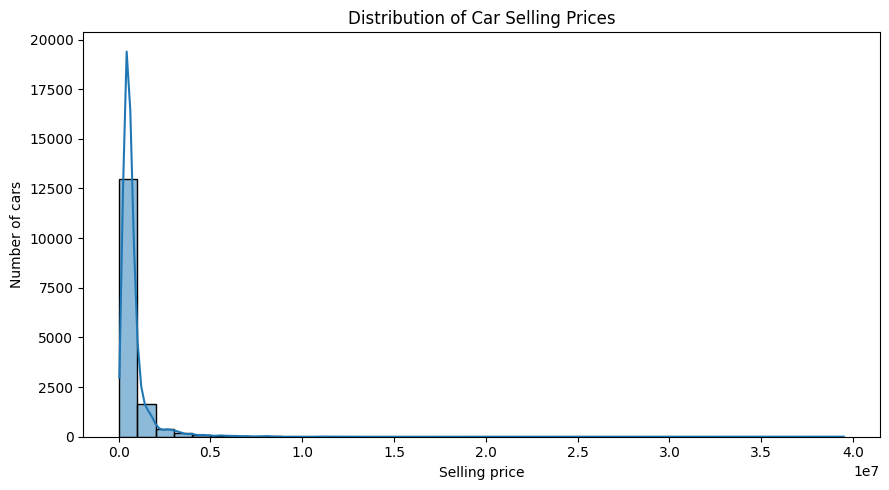

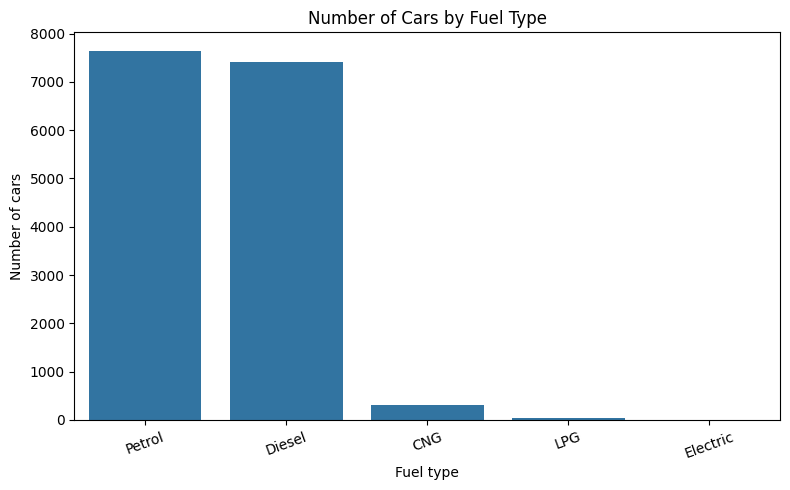

In [ ]:
print("Selling price summary (currency as recorded in the source dataset):")
df.select("selling_price").summary("count", "min", "25%", "50%", "75%", "max", "mean").show()

price_pd = df.select("selling_price").toPandas()
plt.figure(figsize=(9, 5))
sns.histplot(price_pd["selling_price"], bins=40, kde=True)
plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling price")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

fuel_pd = (
    df.groupBy("fuel_type").count()
    .orderBy(F.desc("count"))
    .toPandas()
)
plt.figure(figsize=(8, 5))
sns.barplot(data=fuel_pd, x="fuel_type", y="count")
plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Number of cars")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 7. Creating the target variable: Low / Medium / High

- **Low:** price at or below the 33rd percentile
- **Medium:** price above the 33rd percentile and at or below the 67th percentile
- **High:** price above the 67th percentile

In [ ]:

price_cutoffs = df.approxQuantile("selling_price", [1/3, 2/3], 0.001)
low_cutoff, high_cutoff = price_cutoffs

print(f"Low/Medium boundary (33rd percentile): {low_cutoff:,.2f}")
print(f"Medium/High boundary (67th percentile): {high_cutoff:,.2f}")

df = df.withColumn(
    "price_category",
    F.when(F.col("selling_price") <= low_cutoff, "Low")
     .when(F.col("selling_price") <= high_cutoff, "Medium")
     .otherwise("High")
)

df.groupBy("price_category").count().show()

Low/Medium boundary (33rd percentile): 450,000.00
Medium/High boundary (67th percentile): 700,000.00
+--------------+-----+
|price_category|count|
+--------------+-----+
|           Low| 5481|
|          High| 5098|
|        Medium| 4832|
+--------------+-----+



## 8. Visualizing the price categories

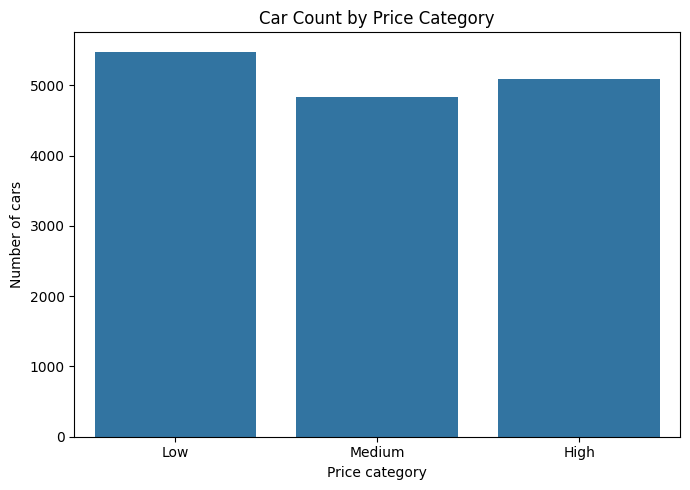

In [9]:
category_order = ["Low", "Medium", "High"]
category_pd = (
    df.groupBy("price_category").count().toPandas()
)
category_pd["price_category"] = pd.Categorical(
    category_pd["price_category"], categories=category_order, ordered=True
)
category_pd = category_pd.sort_values("price_category")

plt.figure(figsize=(7, 5))
sns.barplot(data=category_pd, x="price_category", y="count")
plt.title("Car Count by Price Category")
plt.xlabel("Price category")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

## 9. Selecting model features

Categorical features: `brand`, `fuel_type`, `transmission_type`, `seller_type`.

Numerical features: `vehicle_age`, `km_driven`, `mileage`, `engine`, `max_power`, `seats`.


In [10]:
categorical_features = [
    c for c in ["brand", "fuel_type", "transmission_type", "seller_type"]
    if c in df.columns
]
numeric_features = [
    c for c in ["vehicle_age", "km_driven", "mileage", "engine", "max_power", "seats"]
    if c in df.columns
]

required = categorical_features + numeric_features + ["price_category"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Dataset is missing required columns: {missing_required}")

print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)
print("Target: price_category")

Categorical features: ['brand', 'fuel_type', 'transmission_type', 'seller_type']
Numerical features: ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Target: price_category


## 10. Handling missing feature values

In [ ]:
from pyspark.ml.feature import Imputer

imputed_numeric_features = [f"{c}_imputed" for c in numeric_features]
imputer = Imputer(
    inputCols=numeric_features,
    outputCols=imputed_numeric_features,
    strategy="median"
)

## 11. Encoding categorical variables

In [ ]:
index_output_cols = [f"{c}_index" for c in categorical_features]
encoded_output_cols = [f"{c}_ohe" for c in categorical_features]

indexers = [
    StringIndexer(
        inputCol=input_col,
        outputCol=output_col,
        handleInvalid="keep"
    )
    for input_col, output_col in zip(categorical_features, index_output_cols)
]

encoder = OneHotEncoder(
    inputCols=index_output_cols,
    outputCols=encoded_output_cols,
    handleInvalid="keep"
)

assembler = VectorAssembler(
    inputCols=encoded_output_cols + imputed_numeric_features,
    outputCol="features",
    handleInvalid="keep"
)

# Encode the target labels as 0, 1, 2.
label_indexer = StringIndexer(
    inputCol="price_category",
    outputCol="label",
    stringOrderType="alphabetAsc",
    handleInvalid="keep"
)

## 12. Spliting data into training and testing sets

In [13]:
model_df = df.select(
    *categorical_features,
    *numeric_features,
    "price_category"
)

train_df, test_df = model_df.randomSplit([0.8, 0.2], seed=42)
print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

Training rows: 12390
Testing rows: 3021


## 13. Decision Tree Classifier

In [ ]:
decision_tree = DecisionTreeClassifier(
    labelCol="label",
    featuresCol="features",
    predictionCol="prediction",
    maxDepth=8,
    maxBins=64,
    impurity="gini",
    seed=42
)

pipeline = Pipeline(stages=[imputer] + indexers + [encoder, assembler, label_indexer, decision_tree])

model = pipeline.fit(train_df)
print("Decision Tree pipeline training completed.")

fitted_label_indexer = model.stages[-2]
print("Label mapping (alphabetical order):", fitted_label_indexer.labels)

Decision Tree pipeline training completed.
Label mapping (alphabetical order): ['High', 'Low', 'Medium']


## 14. predictions

In [15]:
predictions = model.transform(test_df)
predictions.select(
    "price_category", "label", "prediction", "probability"
).show(10, truncate=False)

+--------------+-----+----------+--------------------------------------------------+
|price_category|label|prediction|probability                                       |
+--------------+-----+----------+--------------------------------------------------+
|High          |0.0  |0.0       |[0.9968253968253968,0.0,0.0031746031746031746,0.0]|
|High          |0.0  |0.0       |[0.9968253968253968,0.0,0.0031746031746031746,0.0]|
|High          |0.0  |0.0       |[0.9968253968253968,0.0,0.0031746031746031746,0.0]|
|High          |0.0  |0.0       |[1.0,0.0,0.0,0.0]                                 |
|High          |0.0  |0.0       |[1.0,0.0,0.0,0.0]                                 |
|High          |0.0  |0.0       |[1.0,0.0,0.0,0.0]                                 |
|High          |0.0  |0.0       |[1.0,0.0,0.0,0.0]                                 |
|High          |0.0  |0.0       |[1.0,0.0,0.0,0.0]                                 |
|High          |0.0  |0.0       |[1.0,0.0,0.0,0.0]               

## 15. Model Evaluation

In [16]:
metric_names = ["accuracy", "weightedPrecision", "weightedRecall", "f1"]
metrics = {}

for metric_name in metric_names:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric_name
    )
    metrics[metric_name] = evaluator.evaluate(predictions)

metrics_pd = pd.DataFrame({
    "Metric": ["Accuracy", "Weighted Precision", "Weighted Recall", "Weighted F1-score"],
    "Score": [
        metrics["accuracy"],
        metrics["weightedPrecision"],
        metrics["weightedRecall"],
        metrics["f1"]
    ]
})
display(metrics_pd)

print("Evaluation results:")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

,Metric,Score
0,Accuracy,0.821251
1,Weighted Precision,0.824504
2,Weighted Recall,0.821251
3,Weighted F1-score,0.822369


Evaluation results:
accuracy: 0.8213
weightedPrecision: 0.8245
weightedRecall: 0.8213
f1: 0.8224


## 16. Confusion matrix

Class label order: ['High', 'Low', 'Medium']


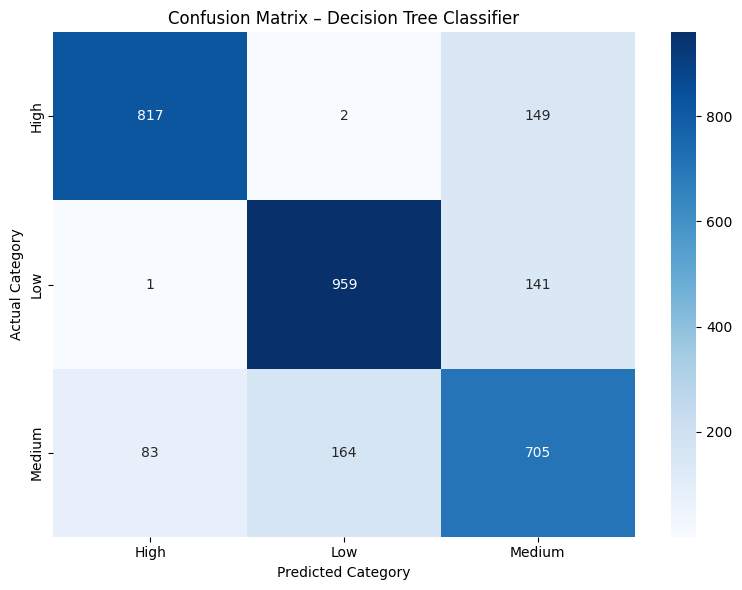

In [ ]:
class_labels = list(fitted_label_indexer.labels)

print("Class label order:", class_labels)

# actual vs predicted combinations.
confusion_data = (
    predictions
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

# confusion matrix.
confusion_table = confusion_data.pivot(
    index="label",
    columns="prediction",
    values="count"
)

class_indices = list(range(len(class_labels)))

confusion_table = confusion_table.reindex(
    index=class_indices,
    columns=class_indices,
    fill_value=0
).fillna(0)

confusion = confusion_table.to_numpy(dtype=int)

# Visualizing the confusion matrix.
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix – Decision Tree Classifier")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

## 17. Feature importance

,Feature,Importance
8,max_power,0.529548
4,vehicle_age,0.295059
7,engine,0.049112
0,brand,0.037436
6,mileage,0.032355
5,km_driven,0.027376
1,fuel_type,0.010531
2,transmission_type,0.009001
9,seats,0.007350
3,seller_type,0.002232


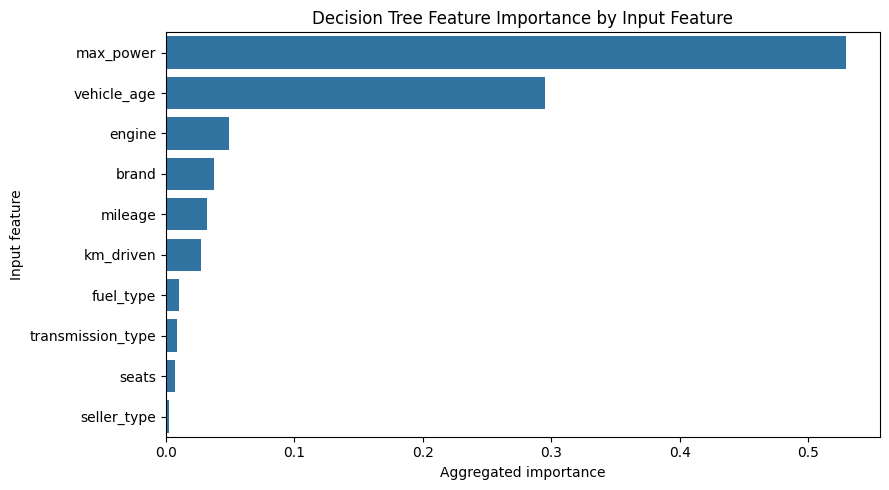

In [ ]:
fitted_tree = model.stages[-1]
importances = fitted_tree.featureImportances.toArray()

assembled_sample = model.transform(train_df.limit(1))
attrs = assembled_sample.schema["features"].metadata.get("ml_attr", {}).get("attrs", {})
attribute_names = {}
for attr_group in attrs.values():
    for attr in attr_group:
        attribute_names[attr["idx"]] = attr.get("name", f"feature_{attr['idx']}")

group_importance = {}
for idx, importance in enumerate(importances):
    feature_name = attribute_names.get(idx, f"feature_{idx}")
    source_feature = feature_name.split("_", 1)[0]
    matched = next(
        (c for c in categorical_features + numeric_features
         if feature_name == c or feature_name.startswith(c + "_")),
        source_feature
    )
    group_importance[matched] = group_importance.get(matched, 0.0) + float(importance)

importance_pd = (
    pd.DataFrame(
        {"Feature": list(group_importance.keys()), "Importance": list(group_importance.values())}
    )
    .sort_values("Importance", ascending=False)
)

display(importance_pd)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_pd, x="Importance", y="Feature")
plt.title("Decision Tree Feature Importance by Input Feature")
plt.xlabel("Aggregated importance")
plt.ylabel("Input feature")
plt.tight_layout()
plt.show()

## 18. Actual vs predicted category comparison

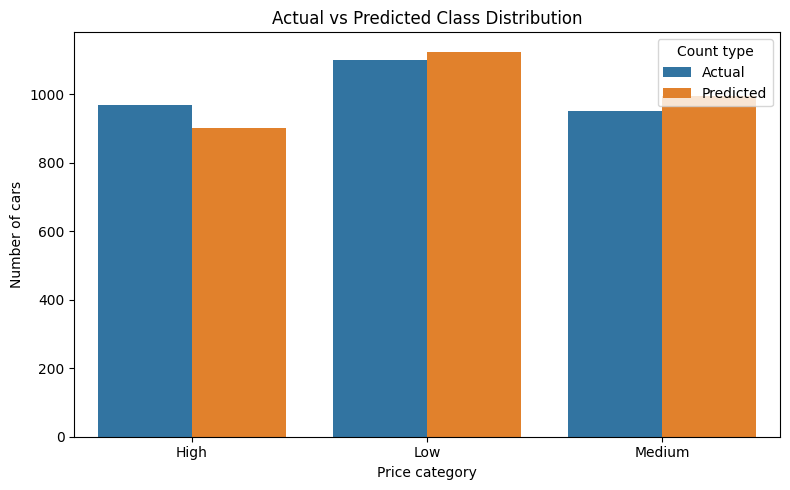

In [ ]:
actual_counts = (
    predictions.groupBy("price_category").count()
    .withColumnRenamed("count", "Actual")
)

label_to_index = {label: index for index, label in enumerate(fitted_label_indexer.labels)}
index_to_label = {float(index): label for label, index in label_to_index.items()}

prediction_to_category = F.create_map(
    *[item for pair in index_to_label.items() for item in (F.lit(pair[0]), F.lit(pair[1]))]
)

predicted_counts = (
    predictions
    .withColumn("predicted_category", prediction_to_category[F.col("prediction")])
    .groupBy(F.col("predicted_category").alias("price_category"))
    .count()
    .withColumnRenamed("count", "Predicted")
)

comparison_pd = (
    actual_counts.join(predicted_counts, "price_category", "outer")
    .fillna(0)
    .toPandas()
)
comparison_pd = comparison_pd.melt(
    id_vars="price_category",
    var_name="Count type",
    value_name="Number of cars"
)

plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_pd, x="price_category", y="Number of cars", hue="Count type")
plt.title("Actual vs Predicted Class Distribution")
plt.xlabel("Price category")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

## 19. Example predictions

In [ ]:
sample_cars = test_df.limit(5)
sample_predictions = model.transform(sample_cars)

sample_predictions.select(
    *categorical_features,
    *numeric_features,
    "price_category",
    "prediction"
).show(truncate=False)

+-----+---------+-----------------+-----------+-----------+---------+-------+------+---------+-----+--------------+----------+
|brand|fuel_type|transmission_type|seller_type|vehicle_age|km_driven|mileage|engine|max_power|seats|price_category|prediction|
+-----+---------+-----------------+-----------+-----------+---------+-------+------+---------+-----+--------------+----------+
|Audi |Diesel   |Automatic        |Dealer     |3.0        |8253.0   |17.68  |1968.0|174.33   |5.0  |High          |0.0       |
|Audi |Diesel   |Automatic        |Dealer     |4.0        |27000.0  |18.53  |1968.0|187.74   |5.0  |High          |0.0       |
|Audi |Diesel   |Automatic        |Dealer     |4.0        |36000.0  |17.11  |1968.0|174.33   |5.0  |High          |0.0       |
|Audi |Diesel   |Automatic        |Dealer     |5.0        |20010.0  |18.53  |1968.0|187.74   |5.0  |High          |0.0       |
|Audi |Diesel   |Automatic        |Dealer     |5.0        |40182.0  |14.75  |2967.0|245.0    |7.0  |High       

In [22]:
spark.stop()
print("Spark session stopped.")

Spark session stopped.
